## Absorption efficiecy vs Photon Energy (MeV)
Si - 2.33 g/cm^2  
&nbsp; thickness - 0.1 cm


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

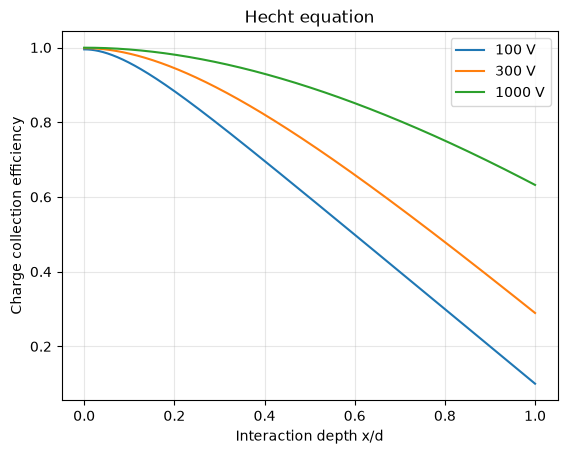

In [3]:
d = 0.1                        # thickness (cm)
mu_tau_e, mu_tau_h = 1e-2, 1e-5  # mobility-lifetime products (cm²/V)
x = np.linspace(0, d, 500)

for V in [100, 300, 1000]:
    E = V / d
    le, lh = mu_tau_e * E, mu_tau_h * E
    cce = (le/d)*(1 - np.exp(-(d - x)/le)) + (lh/d)*(1 - np.exp(-x/lh))
    plt.plot(x/d, cce, label=f"{V} V")

plt.xlabel("Interaction depth x/d")
plt.ylabel("Charge collection efficiency")
plt.title("Hecht equation")
plt.legend(); plt.grid(alpha=.3)
plt.show()

μτ/d² = 0.193 1/V  ->  μτ = 1.93e-03 cm²/V


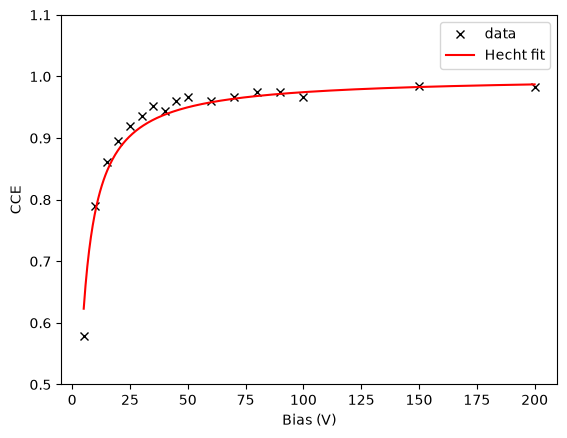

In [ ]:
from scipy.optimize import curve_fit

V = np.array([5,10,15,20,25,30,35,40,45,50,60,70,80,90,100,150,200])
cce = np.array([.578,.79,.862,.895,.92,.936,.952,.944,.96,.967,
                .96,.967,.975,.975,.967,.984,.983])

# k = μτ/d²  (units 1/V), so η = kV·(1 − exp(−1/(kV)))
def hecht(V, k):
    return k*V*(1 - np.exp(-1/(k*V)))

popt, _ = curve_fit(hecht, V, cce, p0=[1.0])
k = popt[0]
print(f"μτ/d² = {k:.3f} 1/V  ->  μτ = {k*d**2:.2e} cm²/V" if (d:=0.1) else "")

Vfit = np.linspace(5, 200, 500)
plt.plot(V, cce, 'kx', label='data')
plt.plot(Vfit, hecht(Vfit, k), 'r-', label='Hecht fit')
plt.xlabel("Bias (V)"); plt.ylabel("CCE")
plt.ylim(0.5, 1.1); plt.legend()
plt.show()

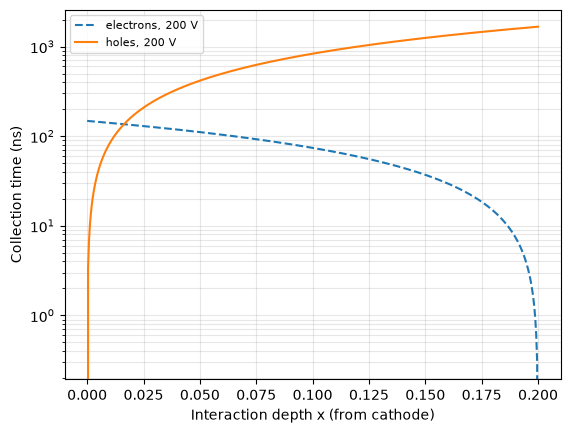

In [5]:
d = 0.2                     # thickness (cm)
mu_e, mu_h = 1350, 120       # mobilities (cm²/V·s), CdZnTe example
x = np.linspace(0, d, 500)   # depth from cathode

for V in [200]:
    E = V / d
    te = (d - x) / (mu_e * E) * 1e9   # ns
    th = x / (mu_h * E) * 1e9         # ns
    plt.plot(x, te, '--', label=f"electrons, {V} V")
    plt.plot(x, th, '-',  label=f"holes, {V} V")

plt.xlabel("Interaction depth x (from cathode)")
plt.ylabel("Collection time (ns)")
plt.yscale("log")
plt.grid(alpha=.3, which='both')
plt.legend(fontsize=8)
plt.show()

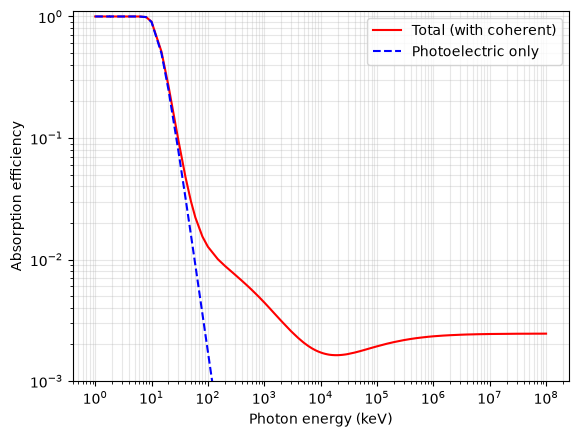

In [ ]:
rho = 2.33    # Si density (g/cm³)
t = 0.03      # thickness (cm)

df = pd.read_csv("data/Si.csv", sep=r"\s+", skiprows=2,
                 names=["E", "pe", "tot"])
df = df.apply(pd.to_numeric, errors="coerce").dropna()

E = df["E"].values * 1000     # MeV to keV
eff_pe  = 1 - np.exp(-df["pe"].values  * rho * t)
eff_tot = 1 - np.exp(-df["tot"].values * rho * t)

plt.loglog(E, eff_tot, 'r-', label='Total (with coherent)')
plt.loglog(E, eff_pe,  'b--', label='Photoelectric only')
plt.xlabel("Photon energy (keV)")
plt.ylabel("Absorption efficiency")
plt.ylim(1e-3, 1.1)
plt.grid(alpha=.3, which='both')
plt.legend()
plt.show()

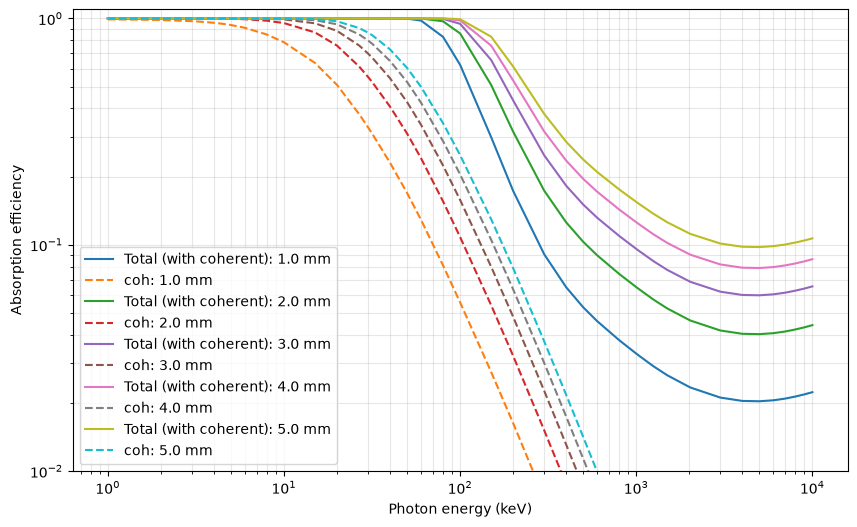

CdTe coh, tot, abs efficiency


In [51]:
# for multiple thickness
rho = 5.85    # CdTe density (g/cm³)
t = [0.1, 0.2, 0.3, 0.4, 0.5]     # thicknesses (cm)

df = pd.read_csv("data/CdTe_coherent.csv", sep=r"\s+", skiprows=2,
                 names=["E", "coh", "tot"]) # mu/rho (cm³/g)
df = df.apply(pd.to_numeric, errors="coerce").dropna()

E = df["E"].values * 1000     # MeV to keV
plt.figure(figsize=(10, 6))
for i in t:
    eff_pe  = 1 - np.exp(-df["coh"].values  * rho * i)
    eff_tot = 1 - np.exp(-df["tot"].values * rho * i)

    plt.loglog(E, eff_tot, label=f'Total (with coherent): {i*10} mm')
    plt.loglog(E, eff_pe,  '--', label=f'coh: {i*10} mm')
plt.xlabel("Photon energy (keV)")
plt.ylabel("Absorption efficiency")
plt.ylim(0.01, 1.1)
plt.grid(alpha=.3, which='both')
plt.legend()
plt.show()

print ('CdTe coh, tot, abs efficiency')

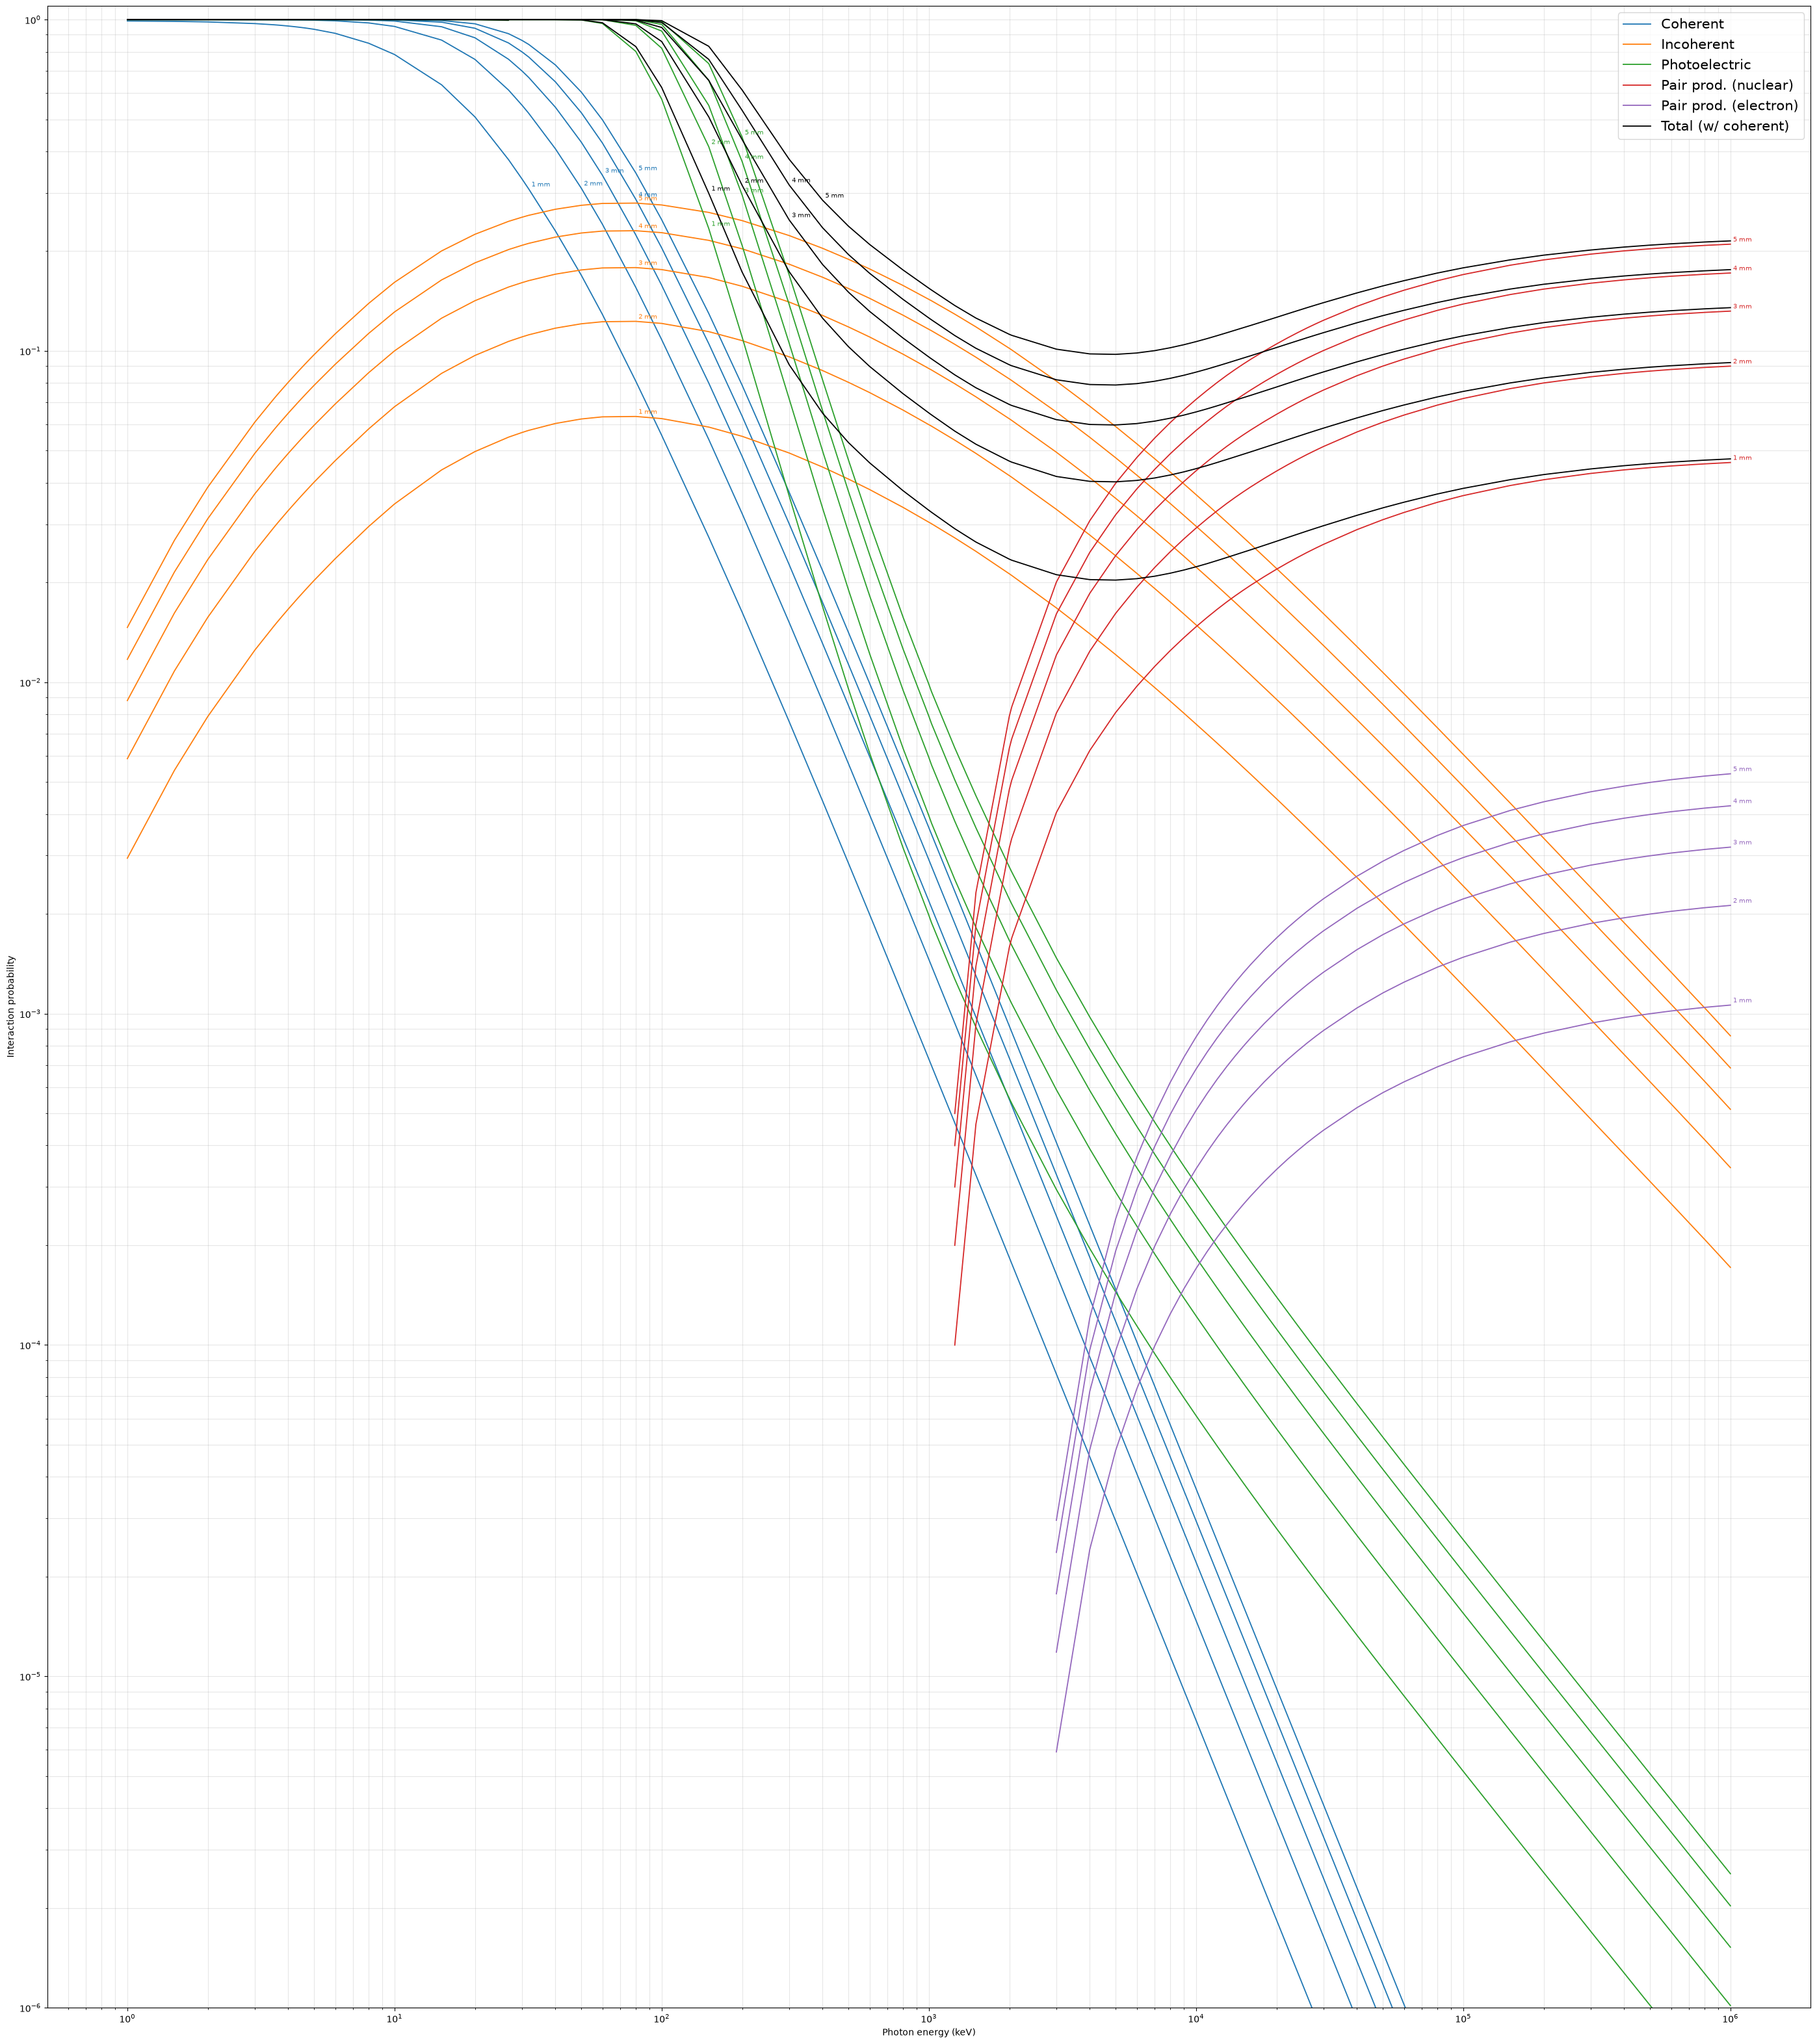

In [ ]:
rho = 5.85                                  # CdTe density (g/cm³)
t = [0.1, 0.2, 0.3, 0.4, 0.5]               # thicknesses (cm) = 1-5 mm

cols = ["E", "coh", "incoh", "pe", "pp_nuc", "pp_el", "tot"]   # mu/rho (cm²/g)
df = pd.read_csv("data/CdTe_all.csv", sep=r"\s+", skiprows=2, names=cols)
df = df.apply(pd.to_numeric, errors="coerce").dropna()
E = df["E"].values * 1000                   # MeV -> keV

types = {
    "coh":    ("Coherent",            "tab:blue"),
    "incoh":  ("Incoherent",          "tab:orange"),
    "pe":     ("Photoelectric",       "tab:green"),
    "pp_nuc": ("Pair prod. (nuclear)","tab:red"),
    "pp_el":  ("Pair prod. (electron)","tab:purple"),
    "tot":    ("Total (w/ coherent)", "black"),
}

ymin, ymax = 1e-6, 1.1
plt.figure(figsize=(35, 40))

for key, (name, color) in types.items():
    for k, th in enumerate(t):
        eff = -np.expm1(-df[key].values * rho * th)
        eff[eff <= 0] = np.nan
        plt.loglog(E, eff, color=color, lw=1.3,
                   label=name if k == 0 else None)   
        
        ok = np.isfinite(eff) & (eff > 1e-5) & (eff < 0.9)
        if ok.any():
            j = np.where(ok)[0][np.argmin(np.abs(np.log10(eff[ok] / 0.3)))]
            plt.annotate(f"{th*10:.0f} mm", (E[j], eff[j]), color=color,
                         fontsize=7, xytext=(3, 3), textcoords="offset points")

plt.xlabel("Photon energy (keV)")
plt.ylabel("Interaction probability")
plt.ylim(ymin, ymax)
plt.grid(alpha=.3, which='both')
plt.legend(fontsize=15)
plt.show()

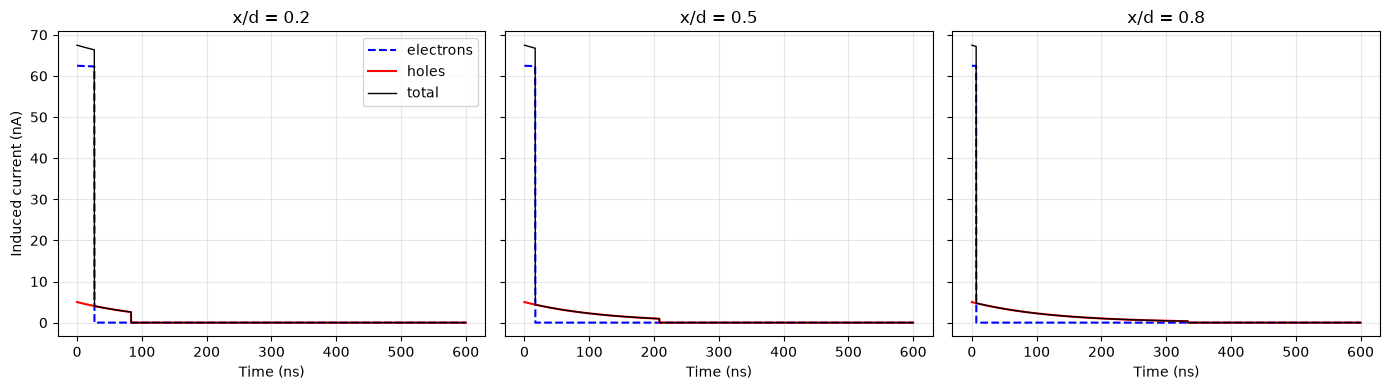

CCE = 0.7429208838671181


In [19]:
q = 1.602e-19
d = 0.1                          # thickness (cm)
V = 300                          # bias (V)
E = V / d                        # field (V/cm)
mu_e, mu_h = 1000, 80            # mobilities (cm²/V·s)
mu_tau_e, mu_tau_h = 1e-2, 1e-5  # (cm²/V)
tau_e, tau_h = mu_tau_e/mu_e, mu_tau_h/mu_h   # lifetimes (s)
N = 13000                        # e-h pairs (~60 keV in CdZnTe)

ve, vh = mu_e*E, mu_h*E          # drift velocities (cm/s)
t = np.linspace(0, 0.6e-6, 5000) # time axis (s)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, x in zip(axes, [0.2*d, 0.5*d, 0.8*d]):   # depth from cathode
    te, th = (d - x)/ve, x/vh
    ie = np.where(t < te, N*q*ve/d*np.exp(-t/tau_e), 0)*1e9   
    ih = np.where(t < th, N*q*vh/d*np.exp(-t/tau_h), 0)*1e9
    ax.plot(t*1e9, ie, 'b--', label='electrons')
    ax.plot(t*1e9, ih, 'r-',  label='holes')
    ax.plot(t*1e9, ie + ih, 'k', lw=1, label='total')
    ax.set_title(f"x/d = {x/d:.1f}")
    ax.set_xlabel("Time (ns)")
    ax.grid(alpha=.3)
axes[0].set_ylabel("Induced current (nA)")
axes[0].legend()
plt.tight_layout()
plt.show()

# Check: integrating the current
x = 0.5*d
te, th = (d - x)/ve, x/vh
Qe = N*q*(ve*tau_e/d)*(1 - np.exp(-te/tau_e))
Qh = N*q*(vh*tau_h/d)*(1 - np.exp(-th/tau_h))
print("CCE =", (Qe + Qh)/(N*q))